# 血糖回归：保留原始特征的改进方案

本 notebook 是 `paper.ipynb` 的独立对照，不修改原文件。主目标为 **降低 MSE**，同时报告 RMSE、MAE、R²。

思路：先固定验证边界，再比较可保留缺失信息和原始阈值关系的提升树。年龄保持原值，未知性别保留为缺失；树模型不做 PCA，不按均值填补，不因缺失多删除预测行。线性基线的填补、标准化置于每个训练折内部。

模型选型只使用训练数据：16 个预先定义候选 → 五折验证（种子 23）→ 前三名以另一五折划分（种子 2026）复核 → 检查前两名等权平均是否降低训练 OOF 误差 → 冻结方案后评估验证集。迭代轮数是预先定义的候选配置，不根据最终验证集早停。

**结果边界：** CV 用于选型，本身存在选择偏差；原验证集、A/B 在此前研究中已经看过，不应把本次结果称为全新、从未触碰的盲测成绩。

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image
from paper_optimized import same_validation, external, make_features
ROOT = Path.cwd()
RESULTS = ROOT / 'review' / 'optimization'
# True 会重新进行两组完整实验；False 直接展示已实际运行并保存的结果。
RUN_SEARCH = False
if RUN_SEARCH:
    same_validation()
    external()
    import subprocess, sys
    subprocess.run([sys.executable, str(RESULTS / 'analyze_results.py')], check=True)
same = json.loads((RESULTS / 'same_validation/results.json').read_text())
full = json.loads((RESULTS / 'external/results.json').read_text())

## 1. 与原 notebook 的同样本比较

读取原 `target.csv` 索引，并核对原始数据血糖逐行一致；使用原 `test_size=0.3, random_state=23` 得到完全相同的 3641 条训练样本和 1561 条验证样本。这一组仅用于公平比较既有样本口径，仍继承了原始删样本形成的人群限制。

原始线性和 XGBoost 40 轮基线已重新拟合复现。神经网络一行取自你本次重跑的已保存输出；因未保存逐条预测，不能对它做配对误差检验。

,MSE,RMSE,MAE,R2
模型,,,,
legacy_linear,1.714056,1.309219,0.803058,0.089320
legacy_xgb_40,1.659235,1.288113,0.753965,0.118447
原神经网络（重跑输出）,1.653400,1.285846,NaN,0.121550
改进：原始特征提升树融合,1.579267,1.256689,0.750444,0.160934


相对原神经网络 MSE 下降： 4.48%
选出的模型： ['lgb_l15_m40_r20_n200', 'hist_l7_r30_n350']


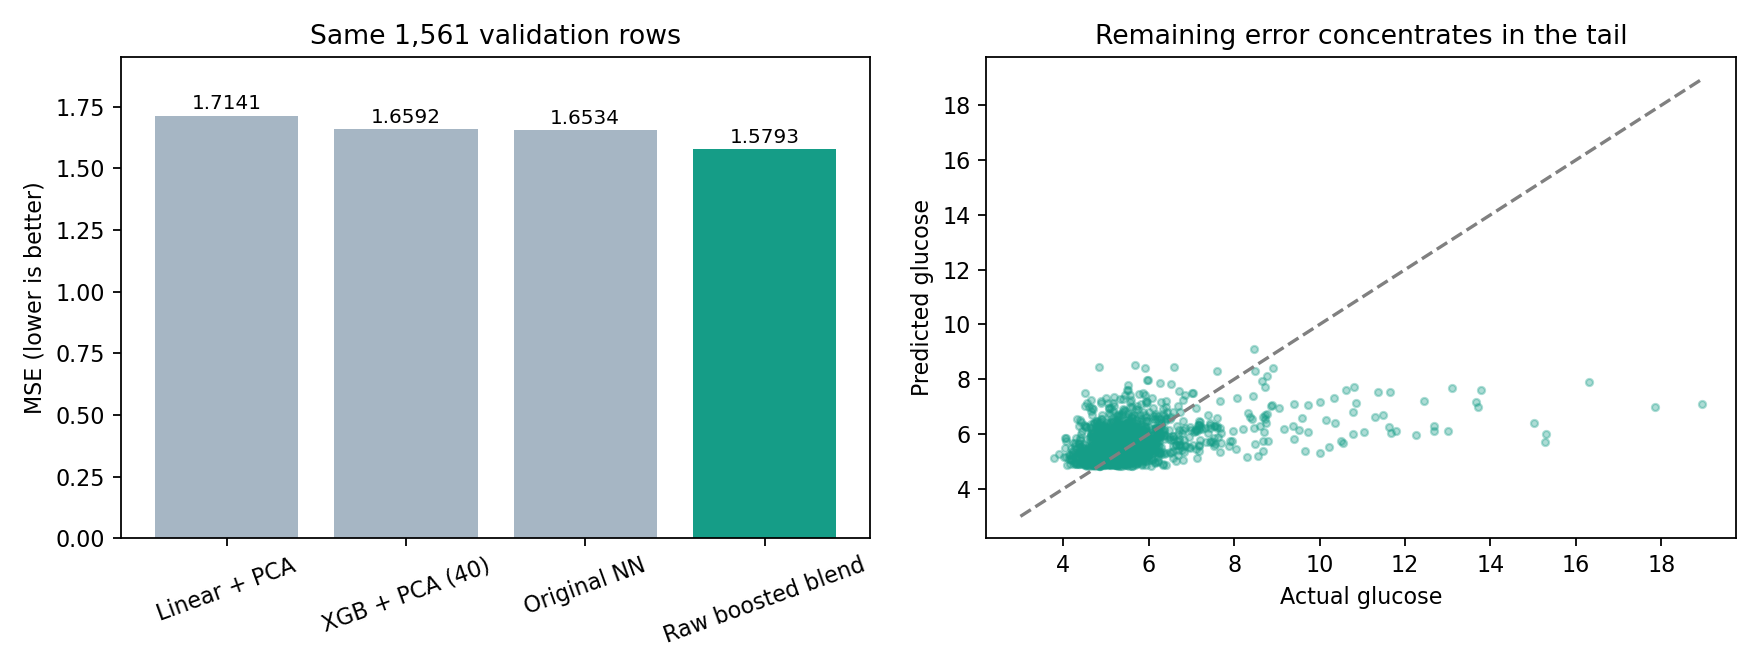

In [2]:
rows = []
for name, m in same['legacy_baselines'].items():
    rows.append({'模型': name, **m})
rows.append({'模型': '原神经网络（重跑输出）', 'MSE': 1.65340, 'RMSE': np.sqrt(1.65340), 'MAE': np.nan, 'R2': 0.12155})
rows.append({'模型': '改进：原始特征提升树融合', **same['evaluations']['validation']['selected']})
comparison = pd.DataFrame(rows).set_index('模型')
display(comparison.round(6))
print('相对原神经网络 MSE 下降：', f"{(1-comparison.iloc[-1]['MSE']/1.65340):.2%}")
print('选出的模型：', same['selection']['members'])
display(Image(filename=str(RESULTS / 'validation_comparison.png')))

## 2. 完整 A/B 集：检验是否能覆盖全部预测样本

这一组只用原始 train 的 5642 条数据训练与选型，A/B 各 1000 条全部保留；A/B 标签不参与本次参数选择或融合权重确定。B 答案必须 `header=None` 读取。

同样的候选选择规则作用于不同训练人群时，可能选出不同配置。下面的完整数据模型才适合用于未清洗的新样本，不能拿它的 A/B 指标直接与原 1561 条随机验证集作大小比较。

日期留出仅是压力检查：模型结构此前已由完整 train 选出，因此不是严格无泄漏的时间外推估计；严格估计需要只在较早区间重新选型并留下新的未来批次。

In [3]:
table=[]
for label, values in full['evaluations'].items():
    for kind in ['ridge_reference', 'selected']:
        table.append({'集合': label, '样本数': values['rows'], '方案': kind, **values[kind]})
display(pd.DataFrame(table).set_index(['集合','方案']).round(6))
print('完整数据选出的模型：', full['selection']['members'])
print('融合权重：', full['selection']['weights'])
display(pd.DataFrame([{'方案': k, **v} for k,v in full['date_stress'].items() if isinstance(v,dict)]).round(6))
print('日期留出分界：', full['date_stress']['cutoff'])

样本数       MSE      RMSE       MAE        R2
集合 方案                                                           
A  ridge_reference  1000  1.792473  1.338833  0.770170  0.145032
   selected         1000  1.730496  1.315483  0.726981  0.174593
B  ridge_reference  1000  1.379045  1.174328  0.713254  0.101995
   selected         1000  1.274190  1.128800  0.659361  0.170275

完整数据选出的模型： ['hist_l7_r30_n350', 'lgb_l7_m60_r30_n350']
融合权重： [0.5, 0.5]


,方案,MSE,RMSE,MAE,R2
0,selected,1.344691,1.159608,0.638467,0.162876
1,ridge_reference,1.389144,1.178620,0.683733,0.135202


日期留出分界： 2017-10-20


## 3. 哪些改动有效：用训练折内消融判断

下面的 `lgb_engineered`、`lgb_no_hepatitis` 与 `lgb_l7_m40_r10_n200` 使用相同模型配置。工程特征包括缺失项目数、若干安全比值与白细胞估算计数；这些都是按行计算，没有读取标签。

本次删去乙肝指标和加入这些工程特征均未稳定改善 CV，因此没有默认采用它们。树模型不依赖线性显著性或 PCA 方差阈值来决定预测特征。

In [4]:
for protocol in ['same_validation','external']:
    cv=pd.read_csv(RESULTS / protocol / 'cv_results.csv')
    print(protocol)
    display(cv[['name','variant','MSE','RMSE','MAE','R2']].round(6))
print('五折复核结果（完整数据）：')
display(pd.DataFrame(full['selection']['finalists']).drop(columns='seed2026_folds').round(6))

same_validation


,name,variant,MSE,RMSE,MAE,R2
0,hist_l7_r30_n350,raw,2.013655,1.419033,0.788330,0.195765
1,lgb_l15_m40_r20_n200,raw,2.016736,1.420118,0.778799,0.194535
2,lgb_l7_m40_r10_n200,raw,2.020009,1.421270,0.778900,0.193228
3,lgb_engineered,engineered,2.020902,1.421584,0.777891,0.192871
4,lgb_l7_m60_r30_n350,raw,2.021696,1.421864,0.793912,0.192554
5,hist_l7_r10_n200,raw,2.027199,1.423797,0.780330,0.190356
6,hist_l15_r30_n200,raw,2.027330,1.423843,0.780219,0.190304
7,lgb_no_hepatitis,no_hepatitis,2.027426,1.423877,0.782545,0.190265
8,lgb_l15_m60_r30_n350,raw,2.031188,1.425198,0.799287,0.188763
9,xgb_d3_m30_r30_n250,raw,2.039158,1.427991,0.779901,0.185580


external


,name,variant,MSE,RMSE,MAE,R2
0,hist_l7_r30_n350,raw,1.947347,1.395474,0.747748,0.183926
1,lgb_l7_m60_r30_n350,raw,1.957366,1.399059,0.752655,0.179727
2,hist_l15_r30_n200,raw,1.964564,1.401629,0.742777,0.176710
3,lgb_l15_m40_r20_n200,raw,1.967007,1.402500,0.747167,0.175687
4,lgb_l15_m60_r30_n350,raw,1.970259,1.403659,0.760156,0.174324
5,lgb_engineered,engineered,1.974438,1.405147,0.744460,0.172573
6,lgb_no_hepatitis,no_hepatitis,1.975388,1.405485,0.745474,0.172174
7,lgb_l7_m40_r10_n200,raw,1.975907,1.405669,0.744495,0.171957
8,hist_l7_r10_n200,raw,1.983675,1.408430,0.745310,0.168701
9,xgb_d3_m30_r30_n250,raw,1.985997,1.409254,0.743778,0.167729


五折复核结果（完整数据）：


,name,seed23_MSE,seed2026_MSE,mean_MSE
0,hist_l7_r30_n350,1.947347,1.962656,1.955001
1,lgb_l7_m60_r30_n350,1.957366,1.960007,1.958686
2,hist_l15_r30_n200,1.964564,1.964024,1.964294


## 4. 剩余误差与不确定性

按真实血糖分组只用于事后诊断，不能将真实血糖区间用于预测分流。检查高血糖尾部是否贡献了不成比例的平方误差，避免靠删去高误差样本制造提升。

配对 bootstrap 区间仅描述当前样本和固定模型的差异，未计入训练随机性、模型搜索及日期相关性；区间跨过 0 时，不应断言稳定优于基线。

In [5]:
display(pd.read_csv(RESULTS / 'target_band_errors.csv').round(5))
uncertainty=json.loads((RESULTS / 'uncertainty.json').read_text())
display(pd.DataFrame(uncertainty).T)
errors=pd.read_csv(RESULTS / 'same_validation/predictions_comparison.csv')
errors['absolute_error']=(errors['prediction']-errors['actual']).abs()
display(errors.nlargest(10,'absolute_error'))

,dataset,target_band,n,MSE,MAE,mean_prediction_minus_actual,fraction_total_SSE
0,same_validation,<6,1267,0.54817,0.55467,0.38654,0.28173
1,same_validation,6-10,258,1.68674,1.02256,-0.85516,0.17653
2,same_validation,>=10,36,37.09810,5.69048,-5.69048,0.54175
3,A,<6,794,0.41392,0.48345,0.28126,0.18992
4,A,6-10,182,1.94521,1.06470,-0.93622,0.20458
5,A,>=10,24,43.65898,6.22262,-6.22262,0.60550
6,B,<6,868,0.47068,0.52110,0.35160,0.32064
7,B,6-10,118,1.75478,0.98669,-0.88406,0.16251
8,B,>=10,14,47.04084,6.47287,-6.47287,0.51686


,MSE_reduction,paired_row_bootstrap_95pct_CI,replicates,limitation
same_vs_legacy_xgb,0.079968,"[0.005710182271622155, 0.16056089403396406]",3000,Conditional on fitted models and these rows; e...
A_vs_ridge,0.061977,"[-0.003088473207575191, 0.1336001071148311]",3000,Conditional on fitted models and these rows; e...
B_vs_ridge,0.104856,"[0.048363079266299444, 0.16711771500825992]",3000,Conditional on fitted models and these rows; e...


,id,actual,prediction,residual,legacy_xgb_prediction,absolute_error
591,5303,18.95,7.107474,11.842526,6.676598,11.842526
42,2983,17.85,6.981334,10.868666,6.480399,10.868666
1006,2065,15.28,5.695756,9.584244,6.386314,9.584244
1029,3317,15.30,6.012575,9.287425,5.562907,9.287425
261,2814,15.02,6.396828,8.623172,5.986890,8.623172
769,128,16.30,7.914571,8.385429,6.778012,8.385429
1047,3647,13.00,6.124512,6.875488,6.381958,6.875488
132,2097,13.70,6.998967,6.701033,6.455256,6.701033
706,5237,12.67,6.103629,6.566371,5.962141,6.566371
1225,1859,13.66,7.158090,6.501910,6.114494,6.501910


## 5. 使用已训练模型预测

`external/selected_model.joblib` 只使用原始 train 训练，保存每个成员模型、特征版本和融合权重。加载本项目自己生成的模型文件即可；新数据的列名应与原始 CSV 一致。预处理函数显式删除 id、日期和血糖，不会使用答案。

下面演示读取 B 集特征预测；这不会重新训练或选择参数。

In [6]:
import joblib
members=joblib.load(RESULTS / 'external/selected_model.joblib')
new_data=pd.read_csv(ROOT / 'data/d_test_B_20180128.csv')
prediction=sum(member['weight'] * member['model'].predict(make_features(new_data,member['variant'])) for member in members)
assert len(prediction)==len(new_data) and np.isfinite(prediction).all()
display(pd.DataFrame({'id':new_data['id'],'预测血糖':prediction}).head(10))

,id,预测血糖
0,6769,5.432874
1,6770,5.520101
2,6771,5.475716
3,6772,5.460093
4,6773,6.420652
5,6774,5.658999
6,6775,5.819791
7,6776,5.145209
8,6777,5.699090
9,6778,5.112297


## 下一步

1. 冻结当前方案后收集新的、未参与开发的验证样本，核实收益能否复现。
2. 若要继续搜索参数，应做嵌套交叉验证或另留新的最终测试集；不要根据现有验证集的最低点反复改轮数。
3. 若要改善尾部误差，应先补充有信息价值的输入或核验数据来源；不要仅凭较高误差就删除真实样本，也不要预设更深网络一定有效。

全部训练实现与候选参数见 `paper_optimized.py`，完整报告和预测明细见 `review/optimization/`。